# 10. Calibración de probabilidades

Comparamos probabilidades originales y calibración sigmoide/isotónica mediante validación cronológica. Las configuraciones son las elegidas en `09g`; no se repite la búsqueda ni se usa el test. El selector de variables (<50% de faltantes), imputación, codificación y escalado se ajustan solo con el tramo base de cada corte.

## Diseño temporal y alcance

| Base del modelo | Calibración | Evaluación |
|---|---:|---:|
| 2007–2011 | 2012 | 2013 |
| 2007–2012 | 2013 | 2014 |
| 2007–2013 | 2014 | 2015 |
| 2007–2014 | 2015 | 2016 |

Cada año evaluado es posterior a los años usados para ajustar el modelo y su calibrador. Sin embargo, el CSV contiene el estado final del préstamo y no registra cuándo se conoció ese desenlace. Como los préstamos duran 36 o 60 meses, no podemos demostrar que las etiquetas de calibración hubieran estado disponibles en el año indicado. Por ello, estos cortes son una validación retrospectiva ordenada por fecha de otorgamiento, pero no prueban por sí solos una simulación operacional estricta. La limitación se debe considerar al interpretar el resultado.

In [3]:
from pathlib import Path
import sys, json, gc, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

RAIZ=Path.cwd()
if not (RAIZ/"src").exists(): RAIZ=RAIZ.parent
if str(RAIZ) not in sys.path: sys.path.insert(0,str(RAIZ))
from src import etapas_finales as ef

SALIDA=RAIZ/"outputs"/"calibracion_probabilidades"
SALIDA.mkdir(parents=True,exist_ok=True)
CFG=json.loads((RAIZ/"outputs"/"optimizacion_final"/"configuracion_reproducible.json").read_text(encoding="utf-8"))
assert CFG["umbral_faltantes_train_pct"]==50
print("Python",platform.python_version(),"pandas",pd.__version__,"numpy",np.__version__)
print("Parámetros definitivos cargados desde 09g:")
for modelo, params in ef.PARAMETROS.items(): print(modelo, params)
print("Semilla:",ef.SEMILLA,"| umbral de faltantes:",ef.UMBRAL_FALTANTES)
config_base={"parametros":ef.PARAMETROS,"umbral_faltantes_entrenamiento_pct":ef.UMBRAL_FALTANTES,
 "cortes":[{"base_hasta":a-2,"calibracion":a-1,"evaluacion":a} for a in ef.ANIOS_VALIDACION],
 "semilla":int(ef.SEMILLA),"maximo_anio_cargado":2016,
 "transformaciones_fit_solo_en_base":True,"indicadores_faltantes":False,
 "calibradores":{"sigmoide":{"implementacion":"Platt con LogisticRegression sobre logit(probabilidad) o margen SVM","C":1e6,"solver":"lbfgs","max_iter":2000,"random_state":int(ef.SEMILLA)},"isotonica":{"out_of_bounds":"clip","y_min":0,"y_max":1}},"python":platform.python_version(),
 "pandas":pd.__version__,"numpy":np.__version__}
(SALIDA/"configuracion_reproducible.json").write_text(json.dumps(config_base,ensure_ascii=False,indent=2),encoding="utf-8")
print("Configuración reproducible guardada.")


Python 3.14.0 pandas 3.0.3 numpy 2.4.6
Parámetros definitivos cargados desde 09g:
regresion_logistica {'C': 0.03148911647956861, 'class_weight': None, 'tol': 8.66211944751964e-05}
svm_lineal {'C': 0.010053940194693016, 'class_weight': 'balanced', 'tol': 0.0001}
gradient_boosting {'learning_rate': 0.05279087869966013, 'max_iter': 200, 'max_leaf_nodes': 25, 'min_samples_leaf': 31, 'l2_regularization': 9.149845592811953}
Semilla: 42 | umbral de faltantes: 50
Configuración reproducible guardada.


## 1. Datos de desarrollo hasta 2016

In [2]:
datos,candidatas,ruta=ef.cargar_desarrollo(ultimo_anio=2016,verbose=True)
X=ef.preparar_X(datos,candidatas)
y=datos["default"].to_numpy(dtype="int8")
anios=datos["anio"].to_numpy(dtype="int16")
print("Fuente:",ruta)
print("Filas elegibles:",f"{len(datos):,}","| candidatas iniciales:",len(candidatas))
print("Años y tamaños:")
print(datos.groupby("anio",observed=True).agg(prestamos=("default","size"),prevalencia=("default","mean")).to_string())
assert anios.max()==2016 and set(np.unique(y))=={0,1}

Bloques leídos: 10; filas fuente recorridas: 1,000,000
Bloques leídos: 20; filas fuente recorridas: 2,000,000
Fuente: C:\Users\josue\Downloads\accepted_2007_to_2018Q4.csv.gz
Filas elegibles: 1,119,699 | candidatas iniciales: 95
Años y tamaños:
      prestamos  prevalencia
anio                        
2007        251     0.179283
2008       1562     0.158131
2009       4716     0.125954
2010      11536     0.128901
2011      21721     0.151789
2012      53367     0.161973
2013     134804     0.155960
2014     223102     0.184494
2015     375545     0.201848
2016     293095     0.232832


## 2. Ajuste, calibración y evaluación por corte

In [3]:
metricas_path=SALIDA/"metricas_por_modelo_metodo_anio.csv"
pred_path=SALIDA/"predicciones_validacion.csv.gz"
vars_path=SALIDA/"variables_por_corte.csv"
metricas=[]; predicciones=[]; variables=[]
if metricas_path.exists() and pred_path.exists() and vars_path.exists():
    metricas=pd.read_csv(metricas_path).to_dict("records")
    predicciones=[pd.read_csv(pred_path,compression="gzip")]
    variables=pd.read_csv(vars_path).to_dict("records")
    completados=set(pd.read_csv(metricas_path).anio_evaluacion.unique())
    print("Checkpoint detectado; se omiten cortes ya guardados:",sorted(completados))
else:
    completados=set()
for anio_eval in ef.ANIOS_VALIDACION:
    if anio_eval in completados:
        continue
    print(f"\nCorte de evaluación {anio_eval}:",flush=True)
    m,p,v=ef.correr_corte(X,y,anios,anio_eval,verbose=True)
    metricas.extend(m.to_dict("records")); predicciones.append(p); variables.extend(v.to_dict("records"))
    pd.DataFrame(metricas).to_csv(metricas_path,index=False,encoding="utf-8-sig")
    pd.concat(predicciones,ignore_index=True).to_csv(pred_path,index=False,compression="gzip",encoding="utf-8-sig")
    pd.DataFrame(variables).drop_duplicates(["anio_evaluacion","variable"]).to_csv(vars_path,index=False,encoding="utf-8-sig")
    print("Checkpoint guardado para",anio_eval,flush=True)
metricas=pd.read_csv(metricas_path)
pred=pd.read_csv(pred_path,compression="gzip")
variables=pd.read_csv(vars_path)
assert set(metricas.anio_evaluacion)==set(ef.ANIOS_VALIDACION)
print("Cortes completos:",metricas.anio_evaluacion.nunique(),"| filas métricas:",len(metricas),"| filas predicciones:",len(pred))


Corte de evaluación 2013:
  regresion_logistica: base hasta 2011 (n=39,786), calibración 2012 (n=53,367), evaluación 2013 (n=134,804); variables=26, transformadas=99.
  svm_lineal: base hasta 2011 (n=39,786), calibración 2012 (n=53,367), evaluación 2013 (n=134,804); variables=26, transformadas=99.
  gradient_boosting: base hasta 2011 (n=39,786), calibración 2012 (n=53,367), evaluación 2013 (n=134,804); variables=26, transformadas=99.
Checkpoint guardado para 2013

Corte de evaluación 2014:
  regresion_logistica: base hasta 2012 (n=93,153), calibración 2013 (n=134,804), evaluación 2014 (n=223,102); variables=26, transformadas=99.
  svm_lineal: base hasta 2012 (n=93,153), calibración 2013 (n=134,804), evaluación 2014 (n=223,102); variables=26, transformadas=99.
  gradient_boosting: base hasta 2012 (n=93,153), calibración 2013 (n=134,804), evaluación 2014 (n=223,102); variables=26, transformadas=99.
Checkpoint guardado para 2014

Corte de evaluación 2015:
  regresion_logistica: base hast

C:\Users\josue\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\josue\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\josue\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\josue\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:261: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as 

## 3. Métricas por año y promedio

In [4]:
metricas_promedio=(metricas.groupby(["modelo","metodo"],as_index=False)
    .agg(ROC_AUC=("ROC_AUC","mean"),PR_AUC=("PR_AUC","mean"),
         Brier_Score=("Brier_Score","mean"),Log_Loss=("Log_Loss","mean"),
         prevalencia_media=("prevalencia","mean"),n_total=("n","sum"),
         ROC_AUC_sd=("ROC_AUC","std"),Brier_sd=("Brier_Score","std")))
metricas_promedio.to_csv(SALIDA/"metricas_promedio.csv",index=False,encoding="utf-8-sig")
metricas.to_csv(SALIDA/"metricas_por_modelo_metodo_anio.csv",index=False,encoding="utf-8-sig")
print("PROMEDIOS DE LOS CUATRO CORTES (para SVM, el margen sin calibrar no se presenta como probabilidad):")
print(metricas_promedio.round(5).to_string(index=False))
print("\nRESULTADOS POR AÑO:")
print(metricas.sort_values(["modelo","metodo","anio_evaluacion"]).round(5).to_string(index=False))
print("\nVariables seleccionadas por corte y modelo (el selector es el mismo criterio para los tres):")
print(variables.groupby(["anio_evaluacion","seleccionada"]).variable.nunique().unstack(fill_value=0).to_string())

PROMEDIOS DE LOS CUATRO CORTES (para SVM, el margen sin calibrar no se presenta como probabilidad):
             modelo    metodo  ROC_AUC  PR_AUC  Brier_Score  Log_Loss  prevalencia_media  n_total  ROC_AUC_sd  Brier_sd
  gradient_boosting Isotónica  0.69710 0.34730      0.14320   0.45230            0.19378  1026546     0.02981   0.01436
  gradient_boosting  Original  0.69736 0.35198      0.14412   0.45339            0.19378  1026546     0.02955   0.01578
  gradient_boosting  Sigmoide  0.69736 0.35198      0.14313   0.45097            0.19378  1026546     0.02955   0.01443
regresion_logistica Isotónica  0.69145 0.34114      0.14408   0.45602            0.19378  1026546     0.02689   0.01479
regresion_logistica  Original  0.69164 0.34539      0.14488   0.45701            0.19378  1026546     0.02673   0.01633
regresion_logistica  Sigmoide  0.69164 0.34539      0.14410   0.45481            0.19378  1026546     0.02673   0.01485
         svm_lineal Isotónica  0.69113 0.34006      0.14411 

## 4. Gráficos de calibración y comparación

Gráficos guardados en C:\Users\josue\Proyecto-ML-Grupo8\outputs\calibracion_probabilidades


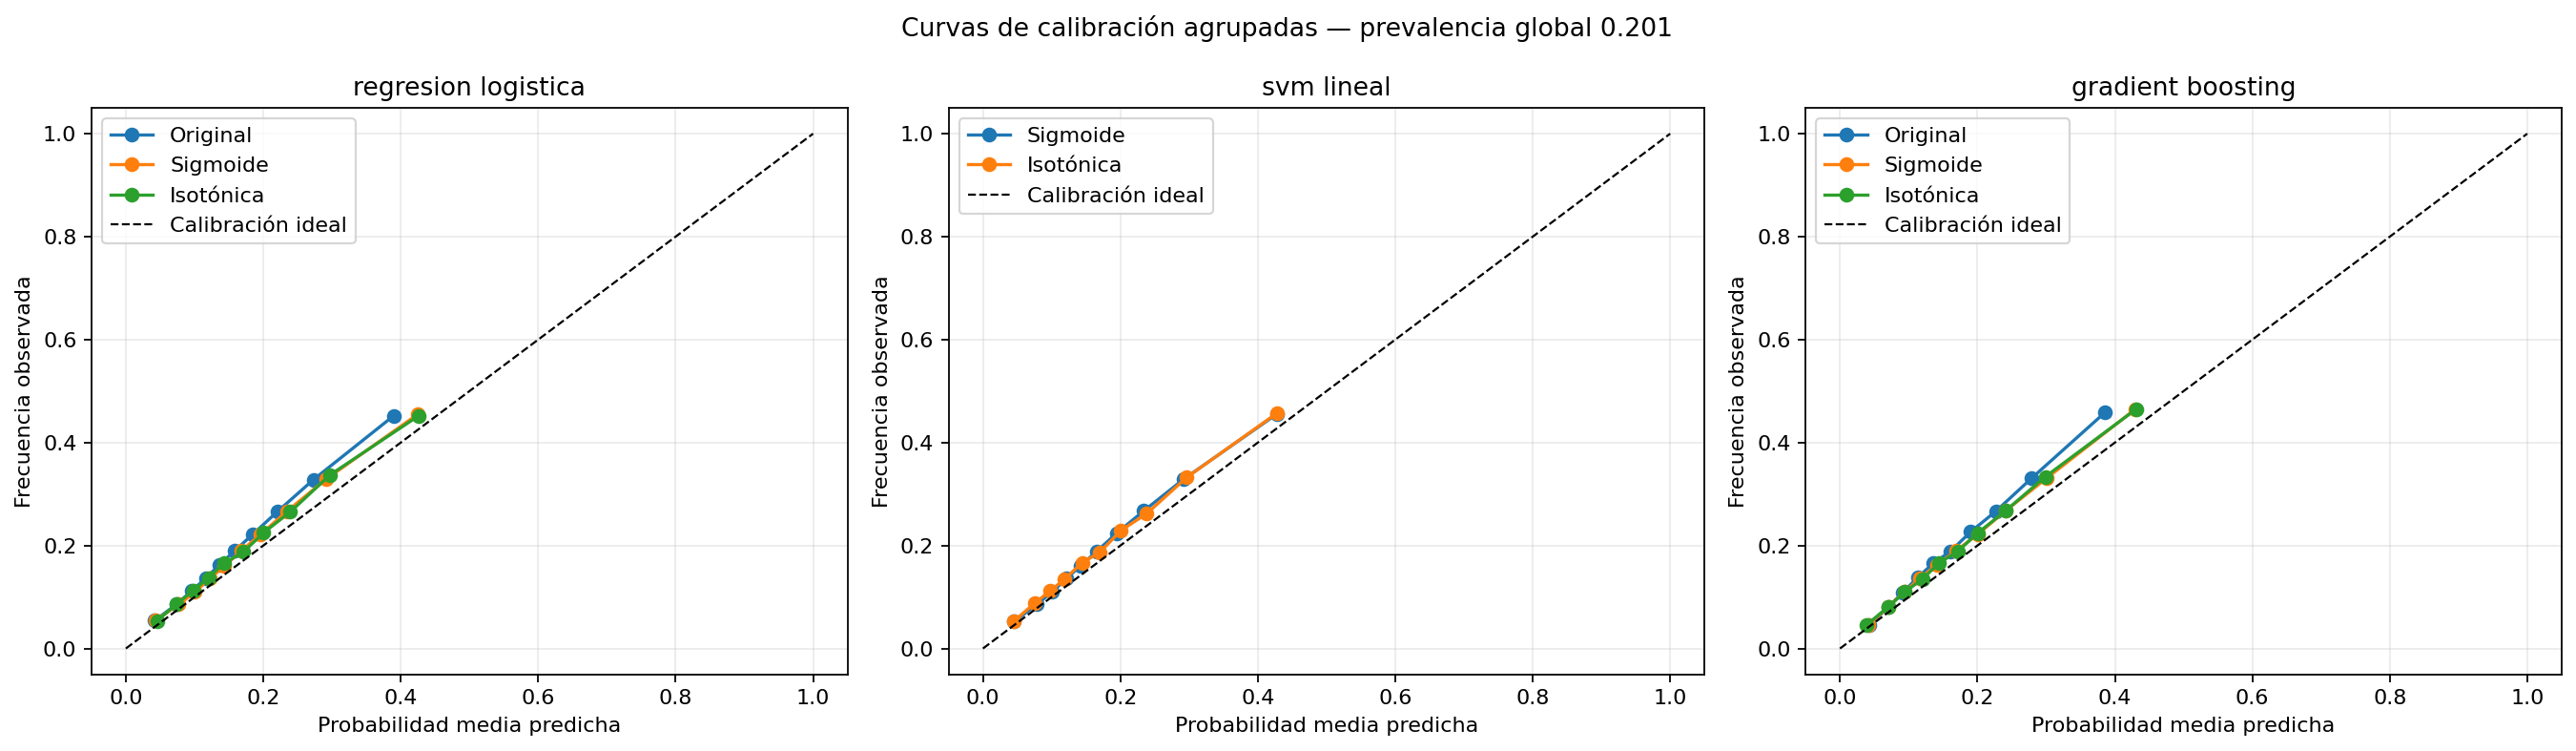

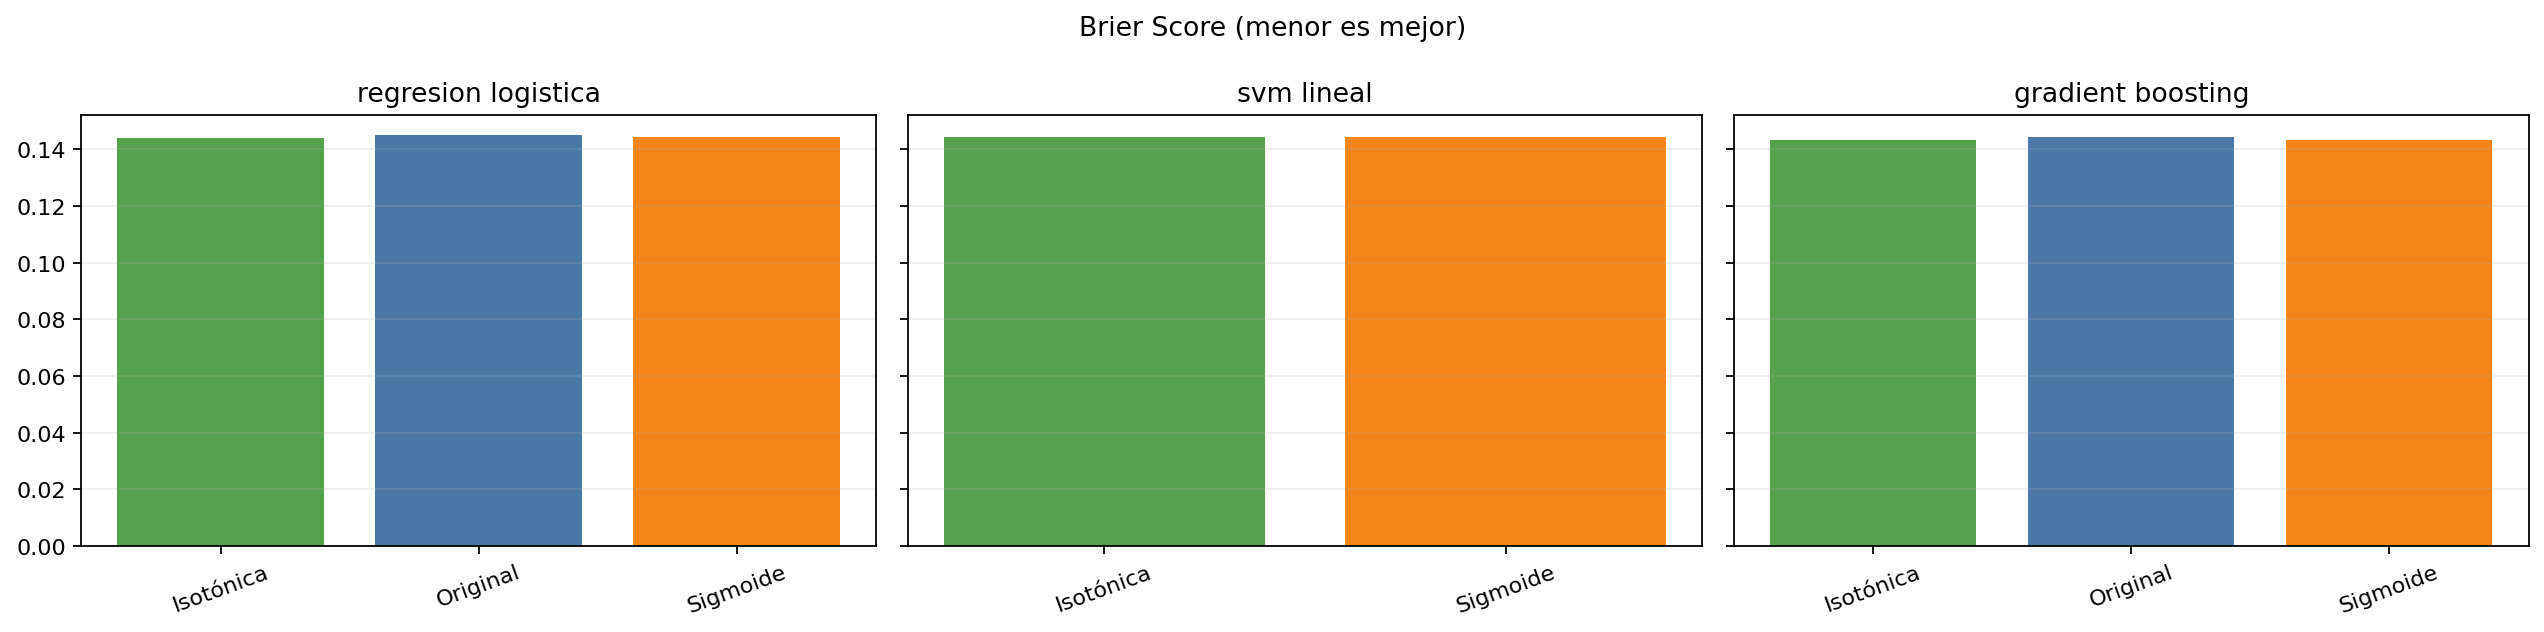

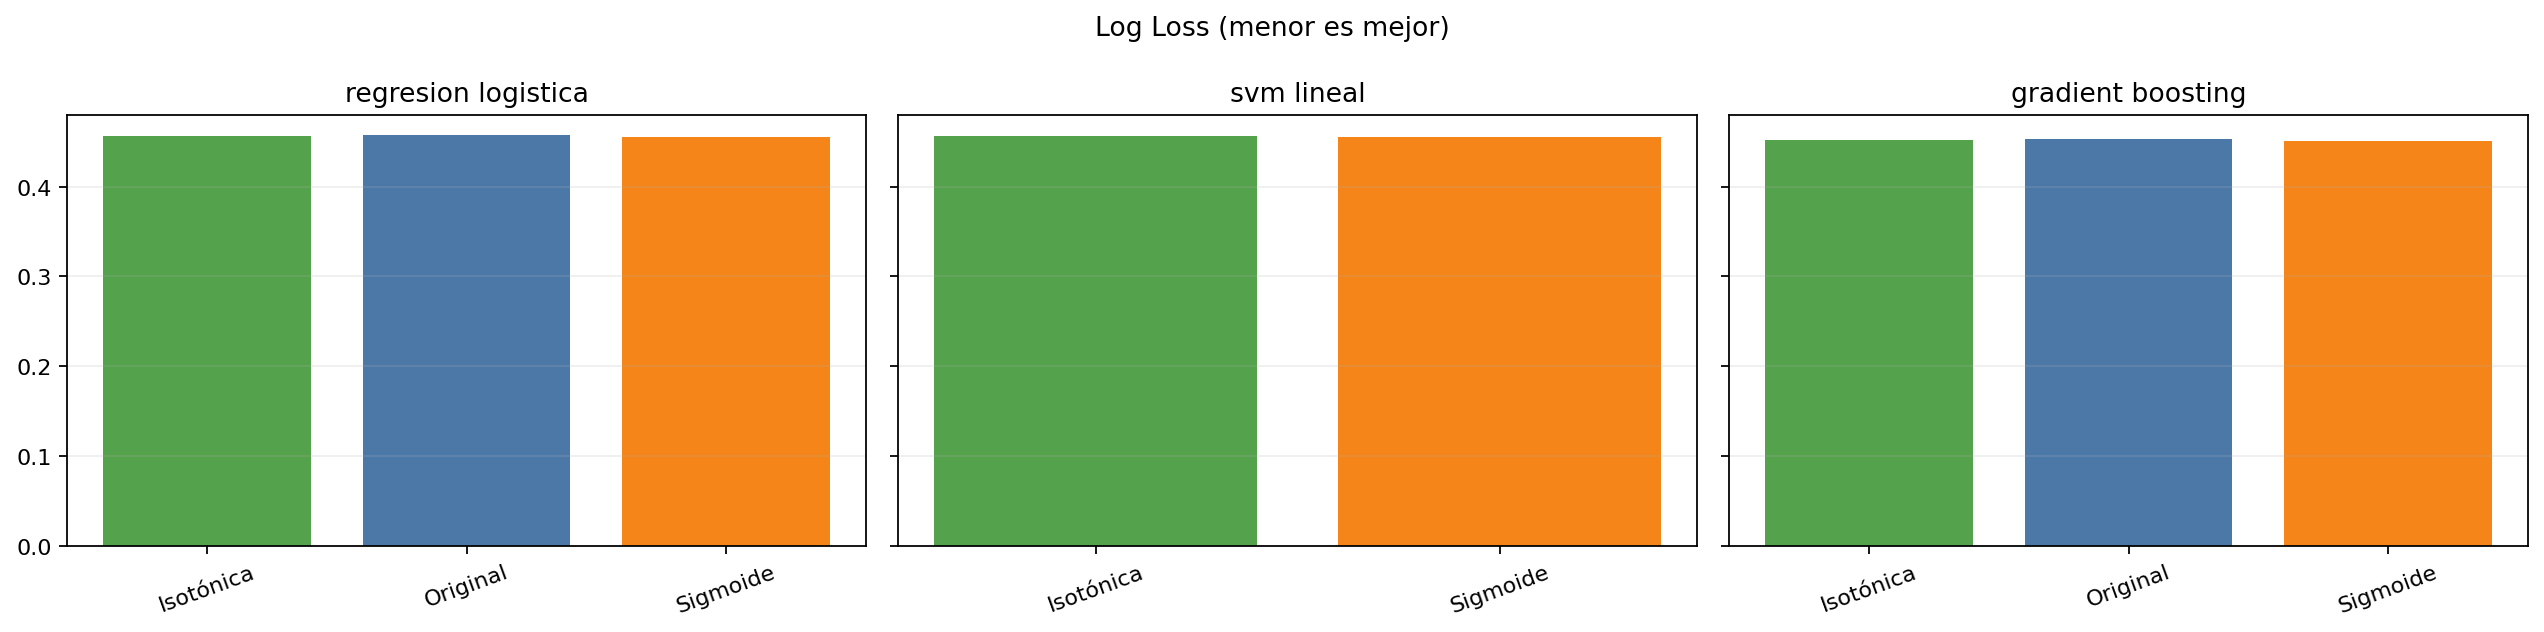

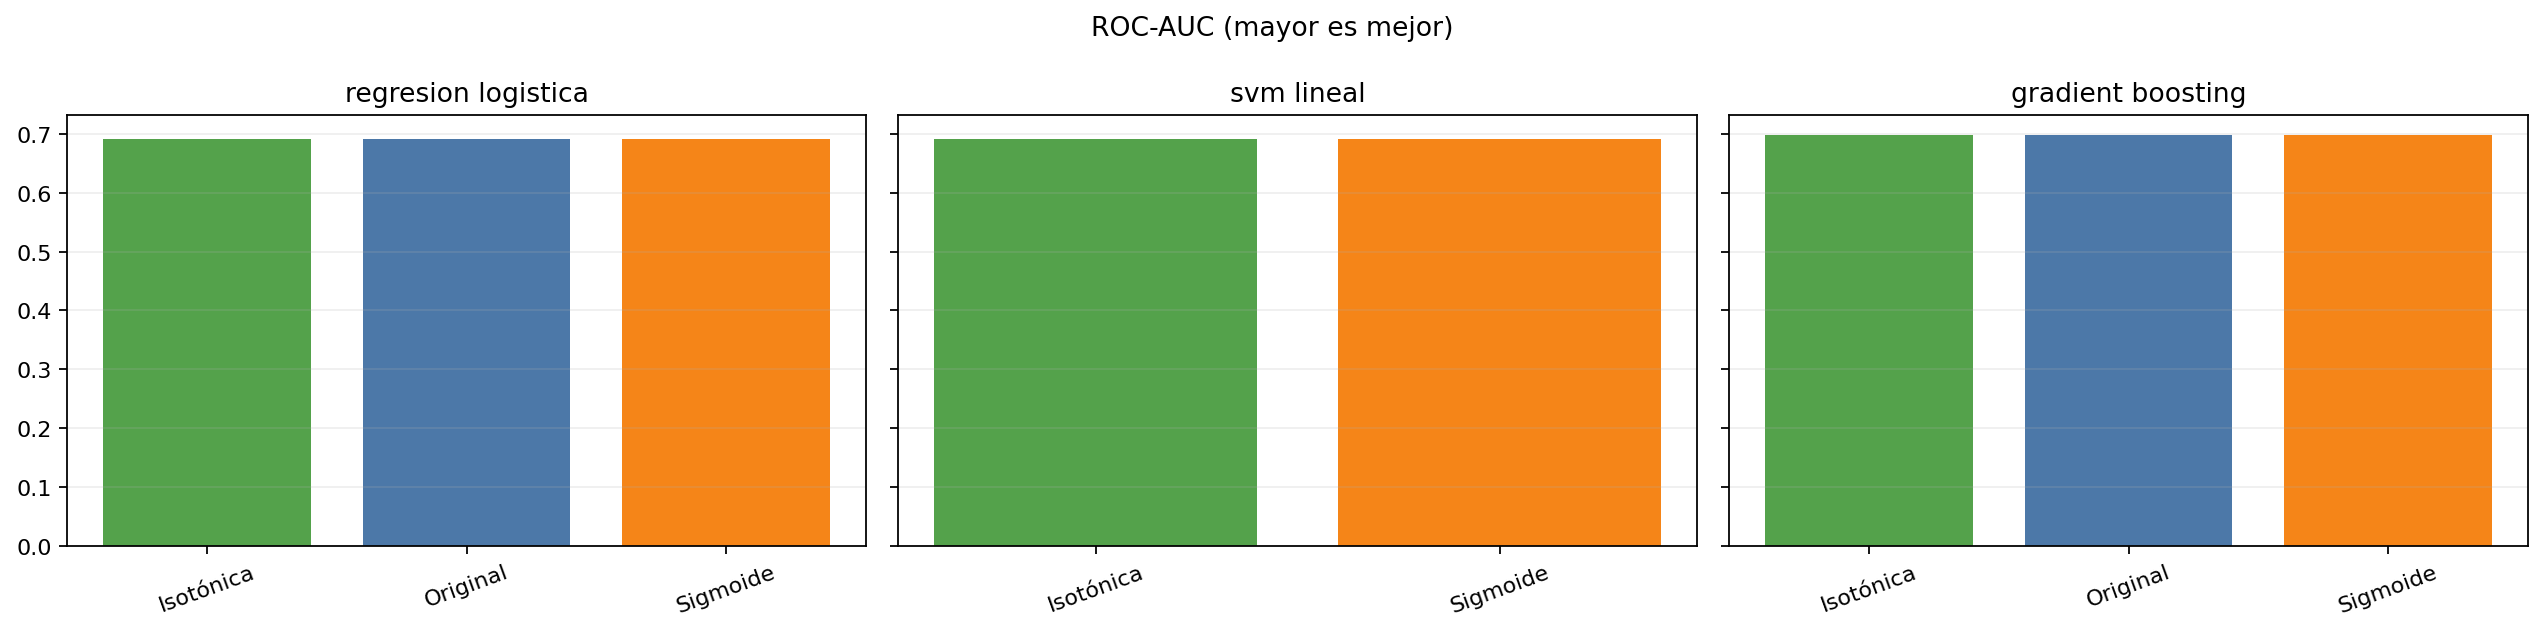

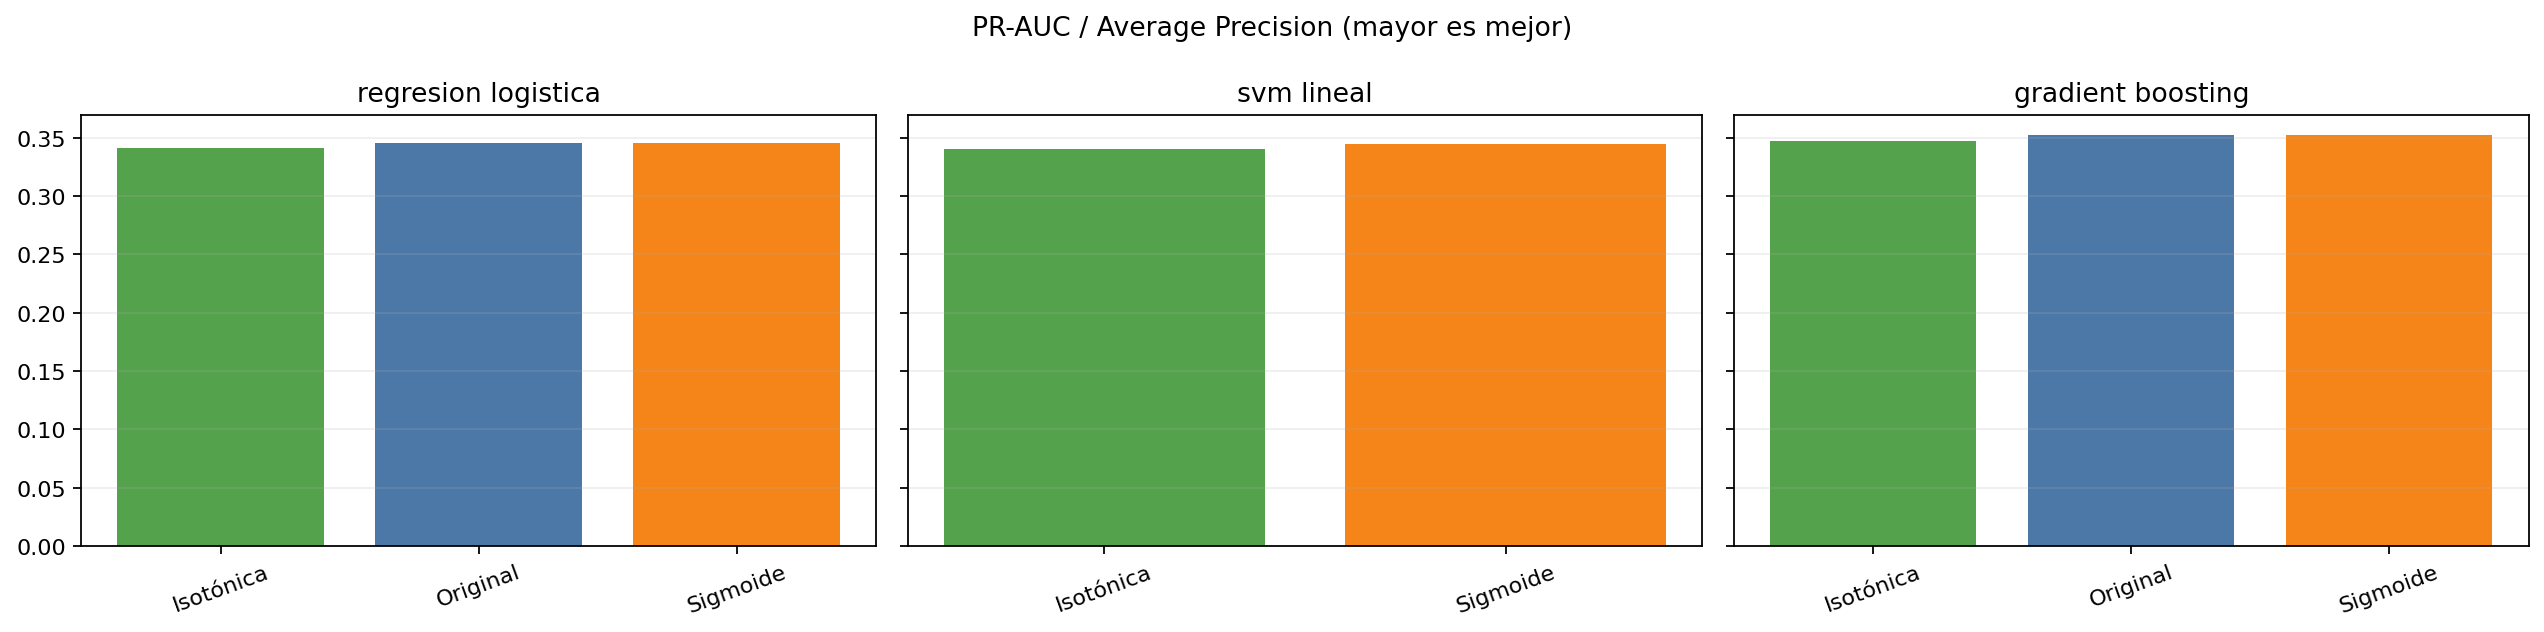

In [5]:
metodos_por_modelo={
 "regresion_logistica":["Original","Sigmoide","Isotónica"],
 "svm_lineal":["Sigmoide","Isotónica"],
 "gradient_boosting":["Original","Sigmoide","Isotónica"]}
# Las curvas agrupadas combinan predicciones fuera de muestra de 2013–2016.
fig,axes=plt.subplots(1,3,figsize=(17,5))
for ax,(modelo,metodos) in zip(axes,metodos_por_modelo.items()):
    sub=pred
    for metodo in metodos:
        col=f"{modelo}__{metodo}"
        frac,mean=calibration_curve(sub.default,sub[col],n_bins=10,strategy="quantile")
        ax.plot(mean,frac,marker="o",label=metodo)
    prevalencia=pred.default.mean()
    ax.plot([0,1],[0,1],"k--",lw=1,label="Calibración ideal")
    ax.set_title(modelo.replace("_"," ")); ax.set_xlabel("Probabilidad media predicha"); ax.set_ylabel("Frecuencia observada")
    ax.grid(alpha=.25); ax.legend()
fig.suptitle(f"Curvas de calibración agrupadas — prevalencia global {prevalencia:.3f}")
fig.tight_layout(); fig.savefig(SALIDA/"01_curvas_calibracion.png",dpi=160,bbox_inches="tight"); plt.close(fig)

for metrica,titulo,archivo in [("Brier_Score","Brier Score (menor es mejor)","02_brier_score.png"),("Log_Loss","Log Loss (menor es mejor)","03_log_loss.png"),("ROC_AUC","ROC-AUC (mayor es mejor)","04_roc_auc.png"),("PR_AUC","PR-AUC / Average Precision (mayor es mejor)","05_pr_auc.png")]:
    fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
    for ax,modelo in zip(axes,metodos_por_modelo):
        s=metricas_promedio[metricas_promedio.modelo==modelo]
        ax.bar(s.metodo,s[metrica],color=["#4C78A8" if x=="Original" else "#F58518" if x=="Sigmoide" else "#54A24B" for x in s.metodo])
        ax.set_title(modelo.replace("_"," ")); ax.tick_params(axis="x",rotation=20); ax.grid(axis="y",alpha=.2)
    fig.suptitle(titulo); fig.tight_layout(); fig.savefig(SALIDA/archivo,dpi=160,bbox_inches="tight"); plt.close(fig)
print("Gráficos guardados en",SALIDA)

## Distribución de probabilidades estimadas

Se comparan las distribuciones agrupadas de 2013–2016 para revisar si la calibración cambia el rango y la concentración de los riesgos estimados.


Gráfico de distribuciones guardado en outputs\calibracion_probabilidades\06_distribucion_probabilidades.png


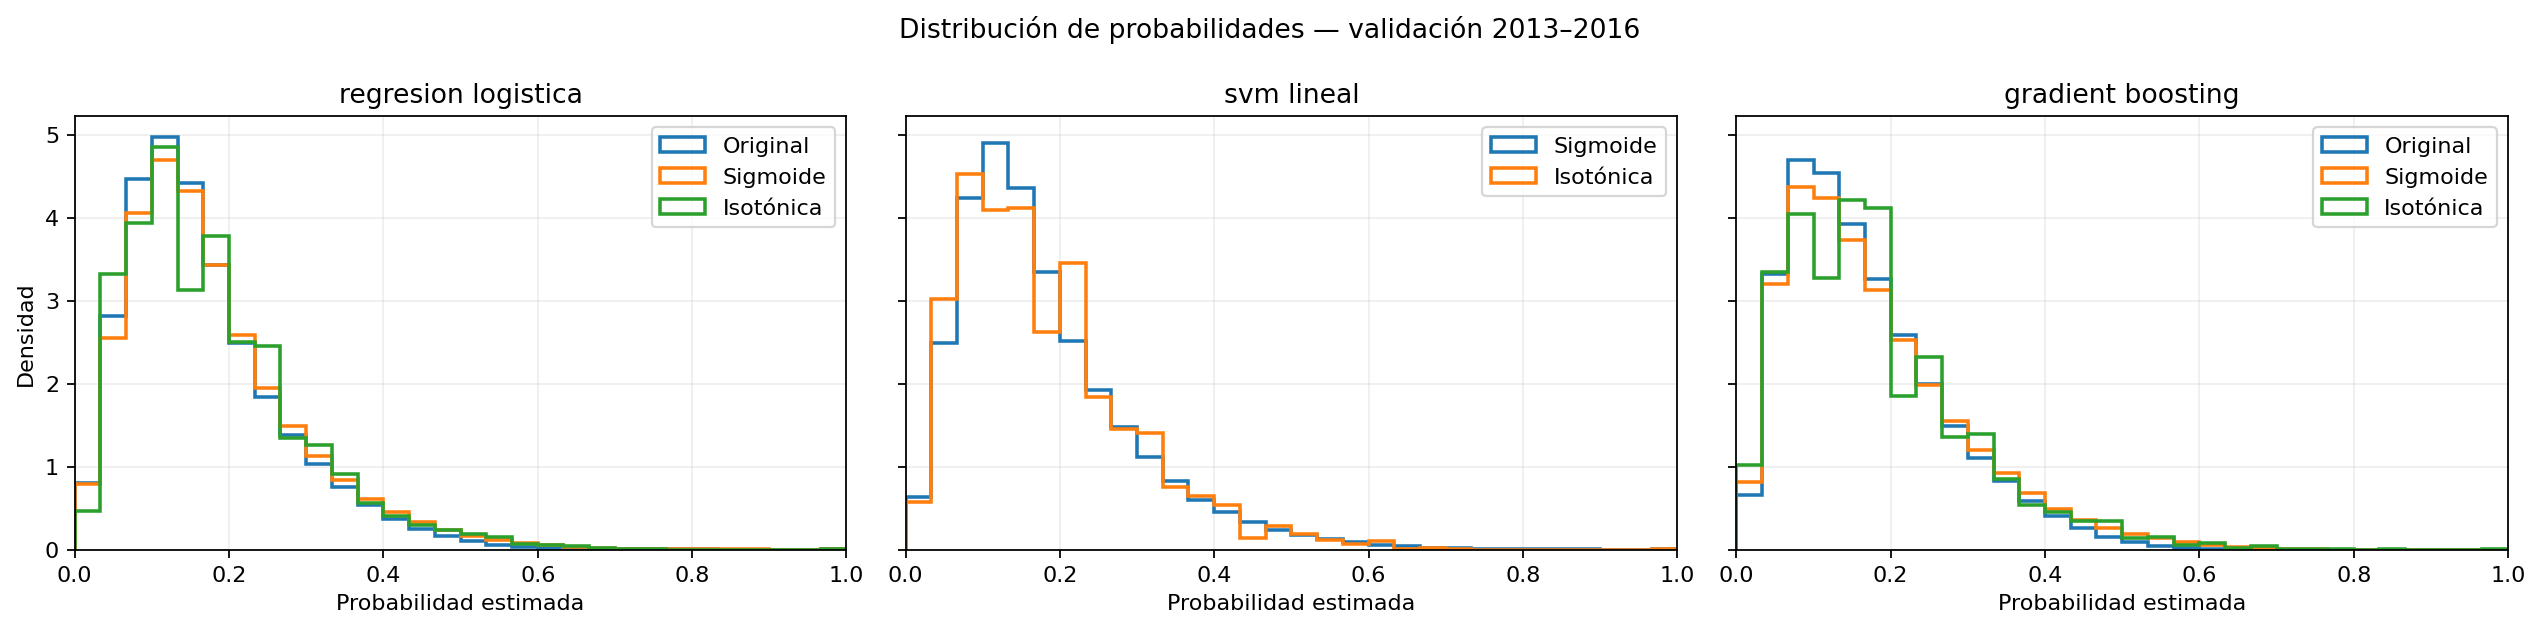

In [12]:
fig,axes=plt.subplots(1,3,figsize=(16,4),sharey=True)
for ax,(modelo,metodos) in zip(axes,metodos_por_modelo.items()):
    for metodo in metodos:
        ax.hist(pred[f"{modelo}__{metodo}"],bins=np.linspace(0,1,31),density=True,
                histtype="step",linewidth=1.6,label=metodo)
    ax.set_xlim(0,1); ax.set_title(modelo.replace("_"," ")); ax.set_xlabel("Probabilidad estimada"); ax.grid(alpha=.2); ax.legend()
axes[0].set_ylabel("Densidad")
fig.suptitle("Distribución de probabilidades — validación 2013–2016")
fig.tight_layout(); fig.savefig(SALIDA/"06_distribucion_probabilidades.png",dpi=160,bbox_inches="tight"); plt.close(fig)
print("Gráfico de distribuciones guardado en",SALIDA/"06_distribucion_probabilidades.png")

## 5. Selección del método por modelo (sin consultar el test)

In [15]:
# Regla explícita: priorizar Brier y Log Loss (probabilidades); si ambos métodos
# están prácticamente empatados (<=0.001 en Brier), conservar los que no
# pierden más de 0.005 de ROC-AUC y elegir entre ellos el menor Log Loss.
selecciones=[]
for modelo, metodos in metodos_por_modelo.items():
    s=metricas_promedio[(metricas_promedio.modelo==modelo)&metricas_promedio.metodo.isin(metodos)].copy()
    minimo=s.Brier_Score.min()
    mejor_roc=s.ROC_AUC.max()
    candidatos=s[(s.Brier_Score<=minimo+0.001)&(s.ROC_AUC>=mejor_roc-0.005)].sort_values(["Log_Loss","Brier_Score","ROC_AUC","PR_AUC"],ascending=[True,True,False,False])
    elegido=candidatos.iloc[0]
    selecciones.append({"modelo":modelo,"metodo_seleccionado":elegido.metodo,
                        "motivo":"Brier a no más de 0.001 del mínimo y ROC-AUC a no más de 0.005 del máximo; entre ellos, menor Log Loss.",
                        "ROC_AUC":elegido.ROC_AUC,"PR_AUC":elegido.PR_AUC,
                        "Brier_Score":elegido.Brier_Score,"Log_Loss":elegido.Log_Loss})
selecciones=pd.DataFrame(selecciones)
selecciones.to_csv(SALIDA/"metodos_seleccionados.csv",index=False,encoding="utf-8-sig")
config_final={"configuracion_base":config_base,"metodos_seleccionados":dict(zip(selecciones.modelo,selecciones.metodo_seleccionado)),
 "regla_seleccion":"Brier <= mínimo + 0.001 y ROC-AUC >= máximo - 0.005; elegir menor Log Loss.",
 "test_consultado":False}
(SALIDA/"configuracion_reproducible.json").write_text(json.dumps(config_final,ensure_ascii=False,indent=2),encoding="utf-8")
print(selecciones.round(5).to_string(index=False))
print("\nCriterios: ROC-AUC/AP miden ordenamiento; Brier/Log Loss miden error probabilístico. La isotónica puede sobreajustarse, sobre todo con pocos casos efectivos por zona de riesgo.")

             modelo metodo_seleccionado                                                                                                  motivo  ROC_AUC  PR_AUC  Brier_Score  Log_Loss
regresion_logistica            Sigmoide Brier a no más de 0.001 del mínimo y ROC-AUC a no más de 0.005 del máximo; entre ellos, menor Log Loss.  0.69164 0.34539      0.14410   0.45481
         svm_lineal            Sigmoide Brier a no más de 0.001 del mínimo y ROC-AUC a no más de 0.005 del máximo; entre ellos, menor Log Loss.  0.69141 0.34446      0.14414   0.45473
  gradient_boosting            Sigmoide Brier a no más de 0.001 del mínimo y ROC-AUC a no más de 0.005 del máximo; entre ellos, menor Log Loss.  0.69736 0.35198      0.14313   0.45097

Criterios: ROC-AUC/AP miden ordenamiento; Brier/Log Loss miden error probabilístico. La isotónica puede sobreajustarse, sobre todo con pocos casos efectivos por zona de riesgo.


## 6. Conclusiones y limitaciones

La tabla de métricas determina si la calibración mejora la calidad de las probabilidades en validación; no se presume que calibrar siempre ayude. Las predicciones y salidas se guardan en `outputs/calibracion_probabilidades/`. La evaluación usa préstamos elegibles con desenlace final y la prevalencia observada puede cambiar por año.

**Límite temporal importante:** `issue_d` solo da la fecha de otorgamiento y `loan_status` refleja el desenlace final del archivo. No existe una fecha de cierre/observación por préstamo que permita probar cuándo se conoció la etiqueta. Por tanto, aunque ningún año de otorgamiento futuro entra en el ajuste de cada corte, no puede garantizarse que las etiquetas de calibración estuvieran maduras en tiempo real. El test de 2017+ también tendrá sesgo de selección porque se evaluará únicamente a préstamos cuyo estado ya es final; la auditoría del notebook 11 cuantifica estados activos y finalizados.